# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Keep the output clean: hide progress bars, load reports and library warnings
import os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"
warnings.filterwarnings("ignore")

from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [3]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [4]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [5]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [6]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

## Solution

### 1. Load `bert-base-uncased` and print layers / heads

In [7]:
from transformers import AutoTokenizer, AutoModel
import torch

bert_name = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name, attn_implementation="eager")
bert_model.eval()

num_layers = bert_model.config.num_hidden_layers
num_heads = bert_model.config.num_attention_heads
print("Transformer layers:", num_layers)
print("Attention heads per layer:", num_heads)

Transformer layers: 12
Attention heads per layer: 12


### 2. Total attention heads across all layers

In [8]:
total_heads = num_layers * num_heads
print(f"Total attention heads = {num_layers} layers x {num_heads} heads = {total_heads}")

Total attention heads = 12 layers x 12 heads = 144


### 3. Attention weights: 3rd layer, 2nd head
Indexing is zero-based, so layer 3 → index `2`, head 2 → index `1`.

In [9]:
import pandas as pd

task_sentence = "Transformers use self-attention to understand language."
task_inputs = bert_tokenizer(task_sentence, return_tensors="pt")
task_tokens = bert_tokenizer.convert_ids_to_tokens(task_inputs["input_ids"][0])

with torch.no_grad():
    task_outputs = bert_model(**task_inputs, output_attentions=True)

print("Number of attention tensors (one per layer):", len(task_outputs.attentions))
print("Shape per layer [batch, heads, seq_len, seq_len]:", tuple(task_outputs.attentions[0].shape))

attn_l3_h2 = task_outputs.attentions[2][0, 1]   # layer 3, head 2
print("Tokens:", task_tokens)
print("Attention matrix shape:", tuple(attn_l3_h2.shape))
print("Each row sums to 1:", torch.allclose(attn_l3_h2.sum(dim=-1), torch.ones(len(task_tokens))))

attn_df = pd.DataFrame(attn_l3_h2.numpy().round(3), index=task_tokens, columns=task_tokens)
attn_df

Number of attention tensors (one per layer): 12
Shape per layer [batch, heads, seq_len, seq_len]: (1, 12, 11, 11)
Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Attention matrix shape: (11, 11)
Each row sums to 1: True


,[CLS],transformers,use,self,-,attention,to,understand,language,.,[SEP]
[CLS],0.732,0.008,0.011,0.006,0.017,0.007,0.010,0.012,0.006,0.039,0.155
transformers,0.889,0.005,0.034,0.000,0.003,0.005,0.001,0.001,0.000,0.005,0.057
use,0.143,0.569,0.005,0.035,0.041,0.068,0.090,0.000,0.005,0.009,0.034
self,0.340,0.073,0.002,0.000,0.202,0.081,0.064,0.026,0.002,0.028,0.183
-,0.143,0.070,0.071,0.639,0.012,0.013,0.003,0.003,0.014,0.009,0.022
attention,0.113,0.545,0.012,0.020,0.111,0.010,0.072,0.000,0.000,0.016,0.100
to,0.084,0.022,0.622,0.008,0.009,0.194,0.011,0.007,0.001,0.014,0.027
understand,0.434,0.005,0.002,0.022,0.012,0.003,0.330,0.002,0.055,0.053,0.082
language,0.051,0.001,0.429,0.002,0.004,0.001,0.005,0.398,0.006,0.041,0.062
.,0.658,0.006,0.003,0.001,0.004,0.003,0.009,0.038,0.046,0.073,0.159


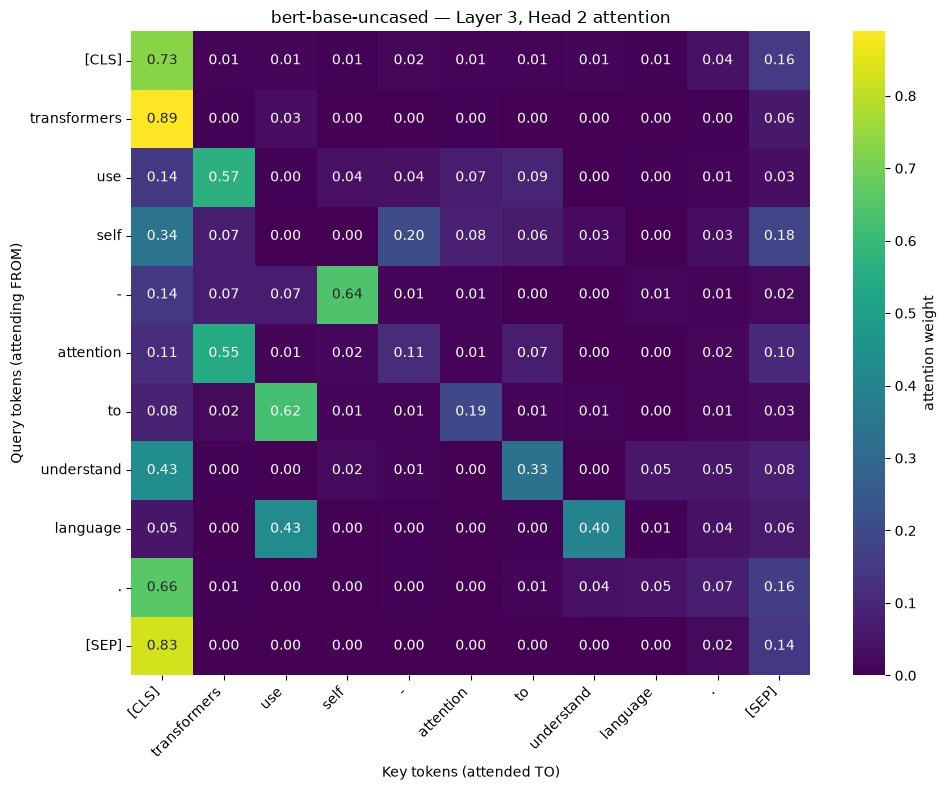

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(attn_df, annot=True, fmt=".2f", cmap="viridis", cbar_kws={"label": "attention weight"})
plt.title("bert-base-uncased — Layer 3, Head 2 attention")
plt.xlabel("Key tokens (attended TO)")
plt.ylabel("Query tokens (attending FROM)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [11]:
# Which token does each token attend to most?
for tok, row in zip(task_tokens, attn_l3_h2):
    j = row.argmax().item()
    print(f"{tok:>12} -> {task_tokens[j]:<12} ({row[j]:.3f})")

       [CLS] -> [CLS]        (0.732)
transformers -> [CLS]        (0.889)
         use -> transformers (0.569)
        self -> [CLS]        (0.340)
           - -> self         (0.639)
   attention -> transformers (0.545)
          to -> use          (0.622)
  understand -> [CLS]        (0.434)
    language -> use          (0.429)
           . -> [CLS]        (0.658)
       [SEP] -> [CLS]        (0.828)


### 4. What do the rows and columns represent?

The matrix is **seq_len × seq_len** (one row and one column for every token, including `[CLS]` and `[SEP]`; note that the tokenizer splits `self-attention` into `self`, `-`, `attention`, giving 11 tokens).

- **Rows = query tokens** — the token that is *doing the attending*. Row *i* shows how token *i* distributes its attention when building its new contextual representation.
- **Columns = key tokens** — the tokens being *attended to*. Entry *(i, j)* is the weight token *i* places on token *j*'s value vector.
- Each row is the output of a **softmax**, so all values are between 0 and 1 and **each row sums to 1** (verified above). Columns do not need to sum to 1.
- A large value at *(i, j)* means token *j* contributes strongly to the updated representation of token *i* in this layer/head. Different heads learn different patterns (e.g. attending to the next/previous token, to `[SEP]`, or to related words).